# NYC 2013 Flight Delays — Exploratory Data Analysis

**Data**: `nycflights13` — 336,776 flights departing EWR, JFK and LGA in 2013, joined to airline,
airport, aircraft and hourly weather tables.

**Goal**: understand *when, where and why* flights are delayed, and turn that into a small set of
recommendations. Every number below comes from the warehouse built by `etl/pipeline.py`; nothing
here is invented or approximated.

**How to read this notebook**: each section states a question, runs SQL or pandas against the
warehouse, and closes with a one- or two-line finding. Figures are saved to `docs/figures/` for
reuse in the README and the dashboard.


In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option('display.max_columns', 30)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['font.size'] = 10.5

FIG_DIR = '../docs/figures'
import os
os.makedirs(FIG_DIR, exist_ok=True)

con = sqlite3.connect('../warehouse/flights.db')

def q(sql):
    return pd.read_sql(sql, con)

COLOR_MAIN = '#1f5c99'
COLOR_ACC  = '#d1495b'
COLOR_GREY = '#9aa3ab'


## 1. Shape of the data

How many flights, what fraction are cancelled or diverted, and what does the raw delay
distribution look like before any slicing?

In [2]:
overview = q('''
    SELECT flight_status, COUNT(*) AS flights,
           ROUND(100.0*COUNT(*)/SUM(COUNT(*)) OVER (), 2) AS pct
    FROM fact_flight GROUP BY flight_status ORDER BY flights DESC
''')
overview


,flight_status,flights,pct
0,Completed,327346,97.20
1,Cancelled,8255,2.45
2,Diverted_or_Incomplete,1175,0.35


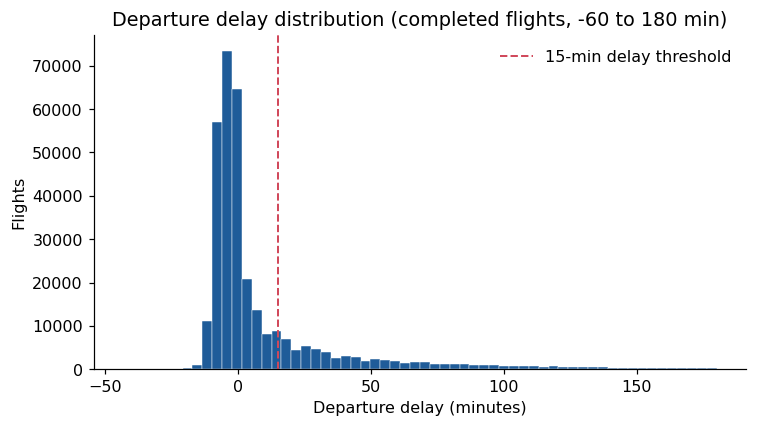

In [3]:
delays = q('''
    SELECT dep_delay_min FROM fact_flight
    WHERE flight_status = 'Completed' AND dep_delay_min BETWEEN -60 AND 180
''')

fig, ax = plt.subplots(figsize=(7,4))
ax.hist(delays.dep_delay_min, bins=60, color=COLOR_MAIN, edgecolor='white', linewidth=0.3)
ax.axvline(15, color=COLOR_ACC, linestyle='--', linewidth=1.3, label='15-min delay threshold')
ax.set_title('Departure delay distribution (completed flights, -60 to 180 min)')
ax.set_xlabel('Departure delay (minutes)'); ax.set_ylabel('Flights')
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/01_delay_distribution.png'); plt.show()


**Finding:** 8,255 flights (2.5%) were cancelled outright and another 1,175 (0.35%) departed
but have no recorded arrival delay (treated as diverted/incomplete). Among completed flights the
delay distribution is right-skewed with a long tail — most flights leave within about 15 minutes
of schedule, but a meaningful minority run very late, which pulls the *average* delay up well
above the *typical* delay. That's why the dashboard leads with delay **rate** (% of flights 15+
min late) rather than average minutes.

## 2. Carrier performance (`sql/analysis/01_carrier_scorecard.sql`, `13_carrier_adjusted_performance.sql`)

Raw delay rates mix two different things: how well a carrier is run, and *where and when* it
happens to schedule its flights. Query 13 adjusts for that with indirect standardisation (each
carrier is benchmarked against every other carrier flying the same airport and scheduled hour).

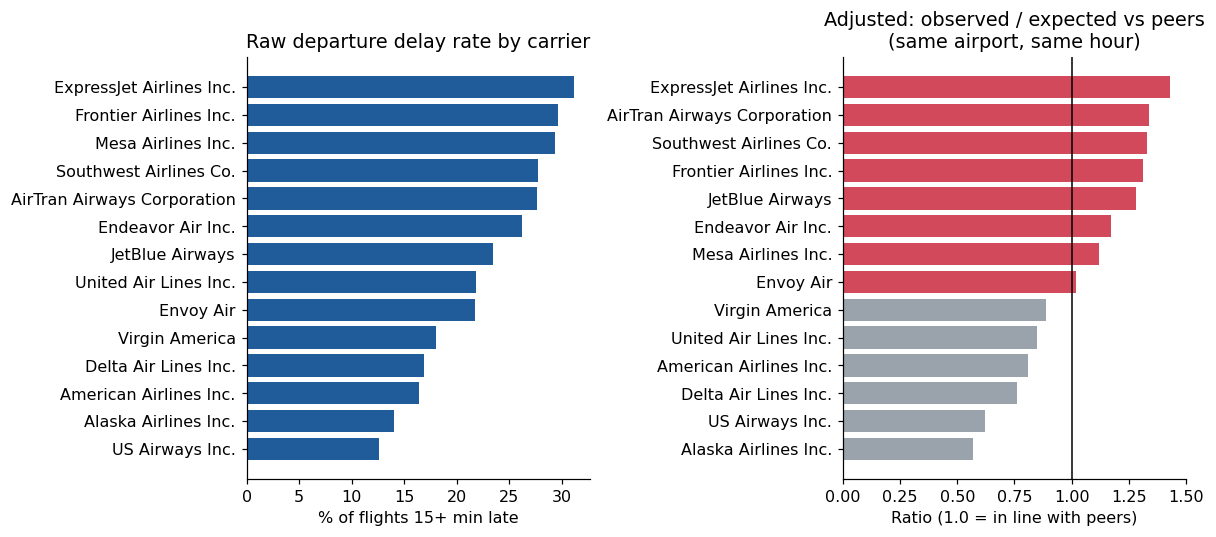

In [4]:
raw = pd.read_csv('../results/01_carrier_scorecard.csv').sort_values('dep_delay_rate_pct', ascending=False)
adj = pd.read_csv('../results/13_carrier_adjusted_performance.csv').sort_values('observed_to_expected', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(11,5), sharey=False)

axes[0].barh(raw.airline_name, raw.dep_delay_rate_pct, color=COLOR_MAIN)
axes[0].invert_yaxis()
axes[0].set_title('Raw departure delay rate by carrier')
axes[0].set_xlabel('% of flights 15+ min late')

colors = [COLOR_ACC if v > 1 else COLOR_GREY for v in adj.observed_to_expected]
axes[1].barh(adj.airline_name, adj.observed_to_expected, color=colors)
axes[1].axvline(1.0, color='black', linewidth=1)
axes[1].invert_yaxis()
axes[1].set_title('Adjusted: observed / expected vs peers\n(same airport, same hour)')
axes[1].set_xlabel('Ratio (1.0 = in line with peers)')

plt.tight_layout(); plt.savefig(f'{FIG_DIR}/02_carrier_raw_vs_adjusted.png'); plt.show()


In [5]:
compare = raw.merge(adj, on='airline_name')[['airline_name','dep_delay_rate_pct','raw_rank_worst','adjusted_rank_worst']]
compare['rank_change'] = compare.raw_rank_worst - compare.adjusted_rank_worst
compare.sort_values('rank_change', key=abs, ascending=False)


,airline_name,dep_delay_rate_pct,raw_rank_worst,adjusted_rank_worst,rank_change
2,Mesa Airlines Inc.,29.36,3,7,-4
4,AirTran Airways Corporation,27.67,5,2,3
1,Frontier Airlines Inc.,29.62,2,4,-2
6,JetBlue Airways,23.47,7,5,2
7,United Air Lines Inc.,21.83,8,10,-2
3,Southwest Airlines Co.,27.74,4,3,1
10,Delta Air Lines Inc.,16.92,11,12,-1
11,American Airlines Inc.,16.42,12,11,1
8,Envoy Air,21.78,9,8,1
9,Virgin America,18.03,10,9,1


**Finding:** ExpressJet (EV) is worst on both the raw and the adjusted view — its delay rate
is 31% and it is still 43% worse than peers flying the exact same airport-hour slots, so its
problem looks operational, not scheduling. AirTran and Southwest move up several places once you
adjust for *when* they fly, meaning part of their raw rate is explained by flying at
naturally-congested times rather than by how the airline itself is run. This is the kind of
distinction a raw leaderboard hides.

## 3. When delays happen — hour, weekday, month (`03`, `08`, `09`)

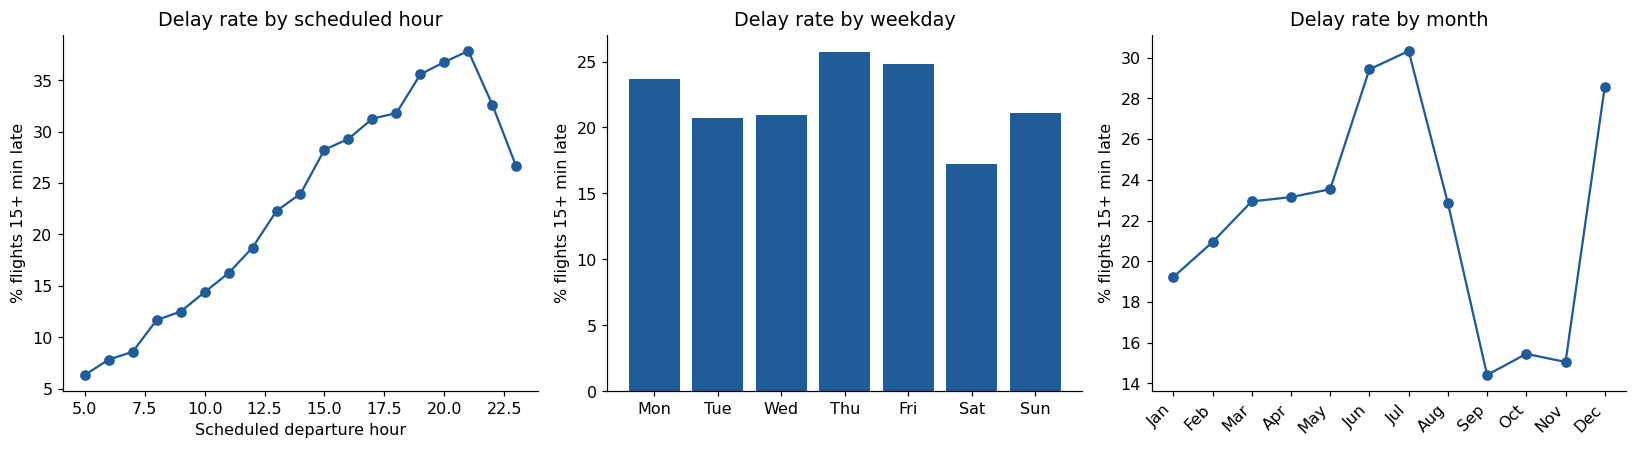

In [6]:
hr = pd.read_csv('../results/03_hour_of_day.csv')
wk = pd.read_csv('../results/09_calendar_effects.csv')
mo = pd.read_csv('../results/08_monthly_seasonality.csv')

fig, axes = plt.subplots(1, 3, figsize=(15,4.2))

axes[0].plot(hr.sched_dep_hour, hr.dep_delay_rate_pct, marker='o', color=COLOR_MAIN)
axes[0].set_title('Delay rate by scheduled hour'); axes[0].set_xlabel('Scheduled departure hour')
axes[0].set_ylabel('% flights 15+ min late')

wkday = wk[wk.dimension=='Weekday'].sort_values('sort_key')
axes[1].bar(wkday.value.str[:3], wkday.dep_delay_rate_pct, color=COLOR_MAIN)
axes[1].set_title('Delay rate by weekday')
plt.setp(axes[1].get_xticklabels(), rotation=0)

axes[2].plot(mo.month_name.str[:3], mo.dep_delay_rate_pct, marker='o', color=COLOR_MAIN)
axes[2].set_title('Delay rate by month')
plt.setp(axes[2].get_xticklabels(), rotation=45, ha='right')

for ax in axes: ax.set_ylabel('% flights 15+ min late') if ax is not axes[0] else None
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/03_when_delays_happen.png'); plt.show()


**Finding:** delay rate climbs steadily through the day — 6-8% at 6 AM vs. over 30% by early
evening — the classic sign of morning delays cascading forward on aircraft rotations (see Section
6). Thursdays and Fridays are worst by weekday; Saturday is calmest. June and July are the worst
months (thunderstorm season), December is elevated by holiday volume, and shoulder months
(April–May, October) are calmest.

## 4. Weather impact (`04`)

Every flight below is one that has a matched hourly weather observation at its own airport
(335,220 of 336,776 flights — see the join-integrity check in Section 8).

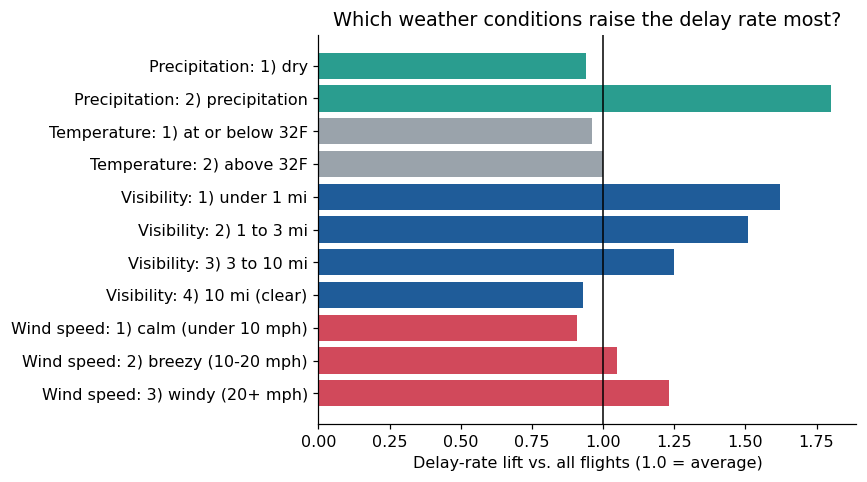

In [7]:
wx = pd.read_csv('../results/04_weather_impact.csv')
fig, ax = plt.subplots(figsize=(8,4.5))
colors = {'Visibility':COLOR_MAIN,'Wind speed':COLOR_ACC,'Precipitation':'#2a9d8f','Temperature':COLOR_GREY}
y = np.arange(len(wx))
ax.barh(y, wx.delay_lift_vs_all, color=[colors[f] for f in wx.factor])
ax.axvline(1.0, color='black', linewidth=1)
ax.set_yticks(y); ax.set_yticklabels(wx.factor + ': ' + wx.band)
ax.invert_yaxis()
ax.set_xlabel('Delay-rate lift vs. all flights (1.0 = average)')
ax.set_title('Which weather conditions raise the delay rate most?')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/04_weather_lift.png'); plt.show()


**Finding:** low visibility is the strongest single lever — under-1-mile visibility runs at
1.6x the normal delay rate and 3.6x the normal cancellation rate. Precipitation nearly doubles
delay rate and more than triples cancellations. Cold temperature alone barely moves the delay
rate, which suggests it's poor visibility and precipitation events (often correlated with cold
fronts) doing the damage, not cold air by itself. This is an association from one year of data at
three airports, not a causal estimate — see the README's limitations section.

## 5. Aircraft age, holding carrier constant (`05`)

Section 2 already showed carriers differ a lot. Before concluding "older planes delay more,"
check whether that holds *within* a single carrier — otherwise an age effect could just be a
carrier effect wearing an age costume (older carriers may run older fleets).

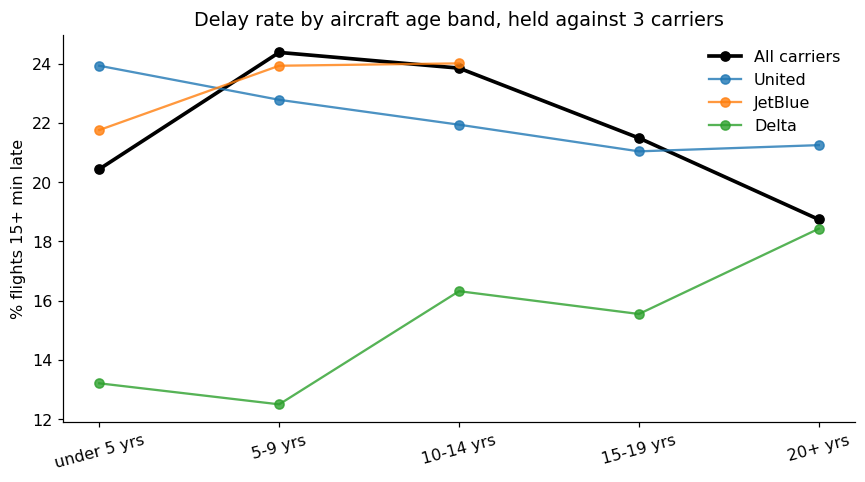

In [8]:
age = pd.read_csv('../results/05_aircraft_age.csv')
fig, ax = plt.subplots(figsize=(8,4.5))
ax.plot(age.age_band.str[3:], age.all_carriers_rate_pct, marker='o', linewidth=2.4, color='black', label='All carriers')
for col, label in [('UA_rate_pct','United'),('B6_rate_pct','JetBlue'),('DL_rate_pct','Delta')]:
    ax.plot(age.age_band.str[3:], age[col], marker='o', alpha=0.8, label=label)
ax.set_title('Delay rate by aircraft age band, held against 3 carriers')
ax.set_ylabel('% flights 15+ min late'); ax.legend(frameon=False)
plt.setp(ax.get_xticklabels(), rotation=15)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/05_aircraft_age.png'); plt.show()


**Finding:** the all-carrier line is nearly flat across age bands (18.7% to 24.4%), and each
individual carrier's line is also close to flat across its own age bands. So the crude story
"older planes cause more delays" doesn't hold up here — most of the variation is between
*carriers*, not between *aircraft ages*. This is a case where a naive one-variable chart (age vs.
delay) would have been misleading; controlling for carrier changes the conclusion.

## 6. Delay propagation through the day (`11`)

Question 3 showed delay rate climbing through the day. Is that pure coincidence of timing (worse
weather later, more congestion later) or does a late aircraft directly hand its delay to its own
next departure?

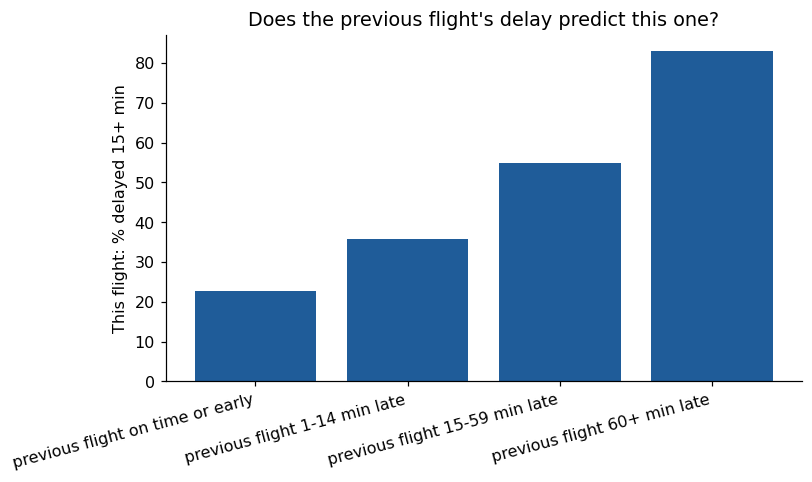

In [9]:
prop = pd.read_csv('../results/11_delay_propagation.csv')
fig, ax1 = plt.subplots(figsize=(7.5,4.5))
x = np.arange(len(prop))
ax1.bar(x, prop.this_flight_delay_rate_pct, color=COLOR_MAIN)
ax1.set_xticks(x); ax1.set_xticklabels([s[3:] for s in prop.previous_flight], rotation=15, ha='right')
ax1.set_ylabel('This flight: % delayed 15+ min')
ax1.set_title('Does the previous flight\'s delay predict this one?')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/06_delay_propagation.png'); plt.show()


**Finding:** this is the strongest relationship in the dataset. When an aircraft's previous
NYC departure that day was on time, its next flight is delayed 22.7% of the time; when the
previous flight was 60+ minutes late, the next flight is delayed 83.0% of the time — nearly a
4x jump. Average gap between an aircraft's departures is about 6.5 hours either way, so this
isn't just "less buffer time"; a genuinely late aircraft is carrying its problem forward. This is
consistent with (though not proof of) delay propagation through aircraft rotations, and it's the
most actionable pattern for an ops team: fixing morning delays pays off all day.

## 7. Where delay minutes concentrate (`07`) and the worst individual routes (`06`)

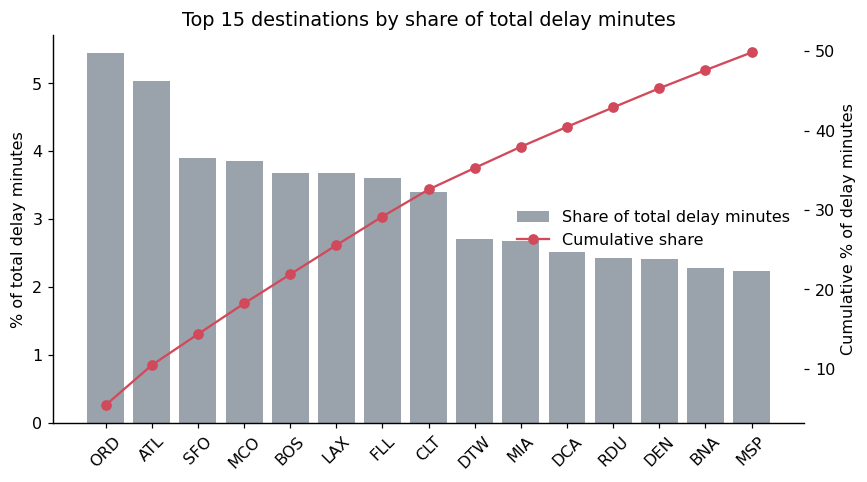

In [10]:
conc = pd.read_csv('../results/07_delay_concentration.csv')
fig, ax = plt.subplots(figsize=(8,4.5))
ax.bar(conc.dest, conc.share_of_delay_pct, color=COLOR_GREY, label='Share of total delay minutes')
ax2 = ax.twinx()
ax2.plot(conc.dest, conc.cumulative_share_pct, color=COLOR_ACC, marker='o', label='Cumulative share')
ax2.set_ylabel('Cumulative % of delay minutes'); ax.set_ylabel('% of total delay minutes')
ax.set_title('Top 15 destinations by share of total delay minutes')
plt.setp(ax.get_xticklabels(), rotation=45)
lines1,l1 = ax.get_legend_handles_labels(); lines2,l2 = ax2.get_legend_handles_labels()
ax.legend(lines1+lines2, l1+l2, frameon=False, loc='center right')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/07_delay_concentration.png'); plt.show()


**Finding:** the top 15 destinations by delay minutes (out of ~100+ served) account for
roughly half of all departure-delay minutes system-wide, led by Chicago O'Hare and Atlanta —
both high-traffic hubs where congestion at the *other* end likely feeds back into NYC departure
delays. This is a Pareto-style concentration: a small set of high-volume, high-congestion routes
matter disproportionately, which is useful for prioritising where an airline would focus
recovery resources.

## 8. Data quality summary

Full detail is in `docs/qa_report.md`, generated automatically by the ETL on every run. The
headline: no FAIL-level issues. One raw error (a 1,048 mph wind reading) was corrected, 4
destination airports were supplemented, and 14.9% of flights don't match a plane record and
0.46% don't match a weather record — both handled with LEFT JOINs and disclosed wherever they
affect a specific analysis (Sections 5's aircraft-age view and Section 4's weather view are each
scoped to their matched subset).

In [11]:
qa = pd.read_csv('../docs/qa_report.md', sep='|', skiprows=0, engine='python') if False else None
with open('../docs/qa_report.md') as f:
    print(f.read().split('## 1.')[0])


# Data quality report

Generated by `etl/pipeline.py` on every run. Nothing here is hand-edited.

Status legend: **PASS** check held, **FIXED** raw problem corrected by the ETL, **WARN** known limitation kept and documented, **FAIL** pipeline stops.

Summary: 44 PASS, 4 FIXED, 7 WARN, 0 FAIL




## 9. Summary of findings

1. **Aircraft rotation is the single strongest driver found.** A 60+ minute late previous flight
   nearly quadruples the odds the next flight is also late (22.7% -> 83.0%).
2. **ExpressJet (EV) underperforms even after adjusting for where/when it flies** (1.43x its
   peer-expected delay rate) — the clearest case of a genuine operational issue rather than a
   scheduling artefact.
3. **Low visibility and precipitation are the weather conditions that matter**; cold temperature
   alone does not move the delay rate much.
4. **Delay risk builds through the day** (6% at 6 AM to 30%+ by evening), consistent with the
   rotation effect compounding hour by hour.
5. **Aircraft age is not a meaningful predictor once carrier is held constant** — a reminder to
   check confounders before trusting a single-variable relationship.
6. **A short list of high-traffic hub destinations (ORD, ATL, SFO, MCO, BOS, LAX...)** account for
   a disproportionate share of total delay minutes.

See `README.md` for the business recommendations built on these findings, and
`docs/dashboard_spec.md` for how they map to the Power BI dashboard.